# Módulo 4 — Autocovariância, ACF e PACF

## Seção 4 — Recursão de Levinson–Durbin e estimação da PACF

**Estado:** material didático para revisão. **Pré-requisitos:** Módulo 4, Seções 1–3; projeção linear, sistemas lineares, ACF teórica e amostral. **Software:** Python 3, NumPy, Matplotlib e Statsmodels. **Natureza dos dados:** exclusivamente simulados.

**Base bibliográfica conferida:** Morettin e Toloi, *Análise de Séries Temporais: modelos lineares univariados*, volume 1, 3ª ed., §5.2.5, pp. impressas 138–139 (pp. 157–158 do PDF), especialmente (5.66)–(5.67): PACF como último coeficiente das equações de Yule–Walker e estimação a partir da ACF. **Complementação didática:** dedução e implementação explícitas da recursão de Levinson–Durbin, exemplo numérico, experimentos e ressalvas computacionais. Não se atribui ao trecho consultado a implementação do algoritmo.

### Objetivos

Entender a motivação de uma solução recursiva; deduzir a atualização dos coeficientes autorregressivos por ordem; interpretar o último coeficiente como PACF; implementar a recursão; comparar com `statsmodels`; compreender quando a recursão pode falhar numericamente.

### 1. Problema: por que não resolver um sistema novo a cada ordem?

Na seção anterior, definimos a PACF de defasagem $k$ como o último coeficiente da melhor previsão **linear** de $X_t=Z_t-\mu$ pelos $k$ valores anteriores:

$$
\widehat X_t^{(k)}=\phi_{k1}X_{t-1}+\cdots+\phi_{kk}X_{t-k},
\qquad \alpha(k)=\phi_{kk}.
$$

Para processos fracamente estacionários, com $\gamma(0)>0$, as equações normais podem ser divididas por $\gamma(0)$:

$$
R_k\boldsymbol\phi_k=\boldsymbol r_k,
$$

onde

$$
R_k=\begin{pmatrix}
1&\rho(1)&\cdots&\rho(k-1)\\
\rho(1)&1&\cdots&\rho(k-2)\\
\vdots&\vdots&\ddots&\vdots\\
\rho(k-1)&\rho(k-2)&\cdots&1
\end{pmatrix},
\quad
\boldsymbol r_k=\begin{pmatrix}\rho(1)\\\rho(2)\\\vdots\\\rho(k)\end{pmatrix}.
$$

A matriz $R_k$ é **Toeplitz**, porque cada diagonal é constante. Resolver separadamente $k$ sistemas de ordens 1 a $k$ desperdiça essa estrutura. A recursão de Levinson–Durbin reaproveita a solução anterior.

**Hipótese técnica:** para as fórmulas com divisão abaixo, assumiremos $R_j$ positiva definida até a ordem desejada. Em particular, as variâncias dos erros de projeção serão positivas. Processos degenerados podem exigir tratamento separado.

### 2. O caso $k=1$ e a primeira variância de erro

Para ordem 1, $\phi_{11}=\rho(1)$. Introduzimos a **variância do erro de projeção normalizada**:

$$
v_k=\frac{\mathrm{Var}(X_t-\widehat X_t^{(k)})}{\gamma(0)}.
$$

Antes de incluir qualquer regressor, $v_0=1$. Após incluir $X_{t-1}$:

$$
\begin{aligned}
v_1&=\frac{\mathrm{Var}(X_t-\rho(1)X_{t-1})}{\gamma(0)}\\
&=1-2\rho(1)^2+\rho(1)^2\\
&=1-\rho(1)^2.
\end{aligned}
$$

É uma razão de variâncias, não a variância original do processo. Se $|\rho(1)|<1$, temos $v_1>0$.

### 3. Dedução da recursão

Suponha conhecidos $\phi_{k-1,1},\ldots,\phi_{k-1,k-1}$ e $v_{k-1}>0$. Queremos acrescentar o regressor $X_{t-k}$ e obter os coeficientes da projeção de ordem $k$.

**Passo 1 — Novo coeficiente parcial.** Aplicando a última equação normal e explorando a simetria da matriz Toeplitz, chega-se a:

$$
\boxed{\kappa_k=\phi_{kk}=
\frac{\rho(k)-\displaystyle\sum_{j=1}^{k-1}\phi_{k-1,j}\rho(k-j)}{v_{k-1}}.}
$$

O numerador é a correlação remanescente, na defasagem $k$, após retirar as contribuições dos regressores já incluídos; o denominador normaliza pelo erro restante da projeção anterior.

**Passo 2 — Atualizar os coeficientes antigos.** Para cada $j=1,\ldots,k-1$:

$$
\boxed{\phi_{kj}=\phi_{k-1,j}-\kappa_k\phi_{k-1,k-j}.}
$$

O índice $k-j$ inverte a ordem dos coeficientes anteriores. Esta inversão vem da simetria das correlações entre observações equidistantes no tempo.

**Passo 3 — Atualizar a variância residual.** A inclusão da nova direção de projeção reduz a variância residual por um fator $1-\kappa_k^2$:

$$
\boxed{v_k=v_{k-1}(1-\kappa_k^2).}
$$

Para justificar o fator, considere os resíduos $A$ e $B$ das projeções de $X_t$ e $X_{t-k}$ sobre as $k-1$ variáveis intermediárias. Por estacionariedade e simetria temporal de suas **matrizes de covariância**, ambos possuem variância $\gamma(0)v_{k-1}$ e correlação $\kappa_k$. A regressão linear de $A$ sobre $B$ deixa variância $\gamma(0)v_{k-1}(1-\kappa_k^2)$. Essa dedução diz respeito a projeções lineares de segunda ordem; não exige independência nem normalidade.

**Condições de validade:** a recursão presume correlações compatíveis com matrizes de covariância não degeneradas. Se $v_{k-1}=0$, a fórmula para $\kappa_k$ não é aplicável. Se o cálculo com estimativas produzir $|\kappa_k|\ge1$ ou $v_k\le0$, é preciso examinar o estimador de ACF, a singularidade e a precisão numérica; não se deve simplesmente continuar dividindo por um número quase nulo.

### 4. Exemplo manual: três ordens

Suponha as autocorrelações teóricas $\rho(0)=1$, $\rho(1)=0{,}6$, $\rho(2)=0{,}2$ e $\rho(3)=0{,}05$. Admitimos que esses valores iniciais integram uma sequência de autocorrelações válida para o cálculo.

**Ordem 1:**

$$
\kappa_1=0{,}6,\qquad v_1=1-0{,}6^2=0{,}64.
$$

**Ordem 2:**

$$
\begin{aligned}
\kappa_2&=\frac{0{,}2-0{,}6\times0{,}6}{0{,}64}=-0{,}25,\\
\phi_{21}&=0{,}6-(-0{,}25)\times0{,}6=0{,}75,\\
\phi_{22}&=-0{,}25,\\
v_2&=0{,}64(1-0{,}25^2)=0{,}60.
\end{aligned}
$$

**Ordem 3:**

$$
\begin{aligned}
\kappa_3
&=\frac{0{,}05-[\phi_{21}\rho(2)+\phi_{22}\rho(1)]}{v_2}\\
&=\frac{0{,}05-[0{,}75(0{,}2)-0{,}25(0{,}6)]}{0{,}60}\\
&=\frac{0{,}05}{0{,}60}=\frac1{12}\approx0{,}08333.
\end{aligned}
$$

Os coeficientes atualizados são $\phi_{31}=0{,}770833\ldots$, $\phi_{32}=-0{,}3125$ e $\phi_{33}=0{,}083333\ldots$. A variância residual normalizada é $v_3\approx0{,}595833$. Observe que **a PACF em cada ordem é apenas o último coeficiente**, não o vetor completo de coeficientes.

### 5. Implementação conceitual em Python

A função abaixo recebe um vetor $[\widehat\rho(0),\ldots,\widehat\rho(K)]$ e retorna as estimativas $\widehat\alpha(1),\ldots,\widehat\alpha(K)$. O laço externo acrescenta uma defasagem por vez; o vetor `a[::-1]` implementa a inversão dos coeficientes anteriores.

In [ ]:
import numpy as np

def levinson_durbin_acf(r, K):
    r = np.asarray(r, dtype=float)
    if len(r) < K + 1 or not np.isclose(r[0], 1):
        raise ValueError("A ACF deve começar em 1 e conter K+1 valores.")

    a = np.array([], dtype=float)
    v = 1.0
    pacf_estim = np.empty(K)

    for k in range(1, K + 1):
        if v <= 1e-12:
            raise ValueError("Sistema degenerado ou mal condicionado.")
        soma = sum(a[j-1] * r[k-j] for j in range(1, k))
        kappa = (r[k] - soma) / v
        if abs(kappa) >= 1:
            raise ValueError("ACF incompatível ou numericamente instável.")
        a = np.r_[a - kappa * a[::-1], kappa]
        v = v * (1 - kappa**2)
        pacf_estim[k-1] = kappa
    return pacf_estim

r = np.array([1.0, 0.6, 0.2, 0.05])
print(levinson_durbin_acf(r, 3))
# [ 0.6        -0.25        0.08333333]


A implementação direta é útil para compreender o algoritmo. Para séries longas e sistemas quase singulares, uma rotina estatística bem testada costuma ser preferível.

### 6. Biblioteca consolidada e comparação reproduzível

A seguir simulamos **um AR(2) estacionário** $Z_t=0{,}6Z_{t-1}-0{,}25Z_{t-2}+\varepsilon_t$. A simulação inicia com um período de aquecimento de 500 observações, descartado, para reduzir a influência das condições iniciais.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.stattools import acf, pacf

rng = np.random.default_rng(20261117)
n = 1200
ar2 = ArmaProcess(np.array([1, -0.6, 0.25]), np.array([1]))
z = ar2.generate_sample(
    nsample=n, burnin=500, distrvs=rng.standard_normal
)

K = 18
r_amostral = acf(z, nlags=K, fft=True)
pacf_manual = levinson_durbin_acf(r_amostral, K)
pacf_biblioteca = pacf(z, nlags=K, method="ywm")[1:]

print(np.max(np.abs(pacf_manual - pacf_biblioteca)))
# Erro numérico próximo de zero

k = np.arange(1, K + 1)
plt.figure(figsize=(9, 4))
plt.vlines(k, 0, pacf_manual, label="Recursão manual")
plt.plot(k, pacf_biblioteca, "o", label="Statsmodels: ywm")
plt.xlabel("Defasagem k")
plt.ylabel("PACF estimada")
plt.title("PACF do AR(2) simulado")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


**Parâmetros:** `nlags` define a maior defasagem; `fft=True` acelera a ACF; `method="ywm"` solicita o método de Yule–Walker com autocovariâncias normalizadas pelo número total de observações (MLE). Diferentes métodos de PACF, como OLS ou variantes de Yule–Walker, podem dar estimativas diferentes em amostras finitas.

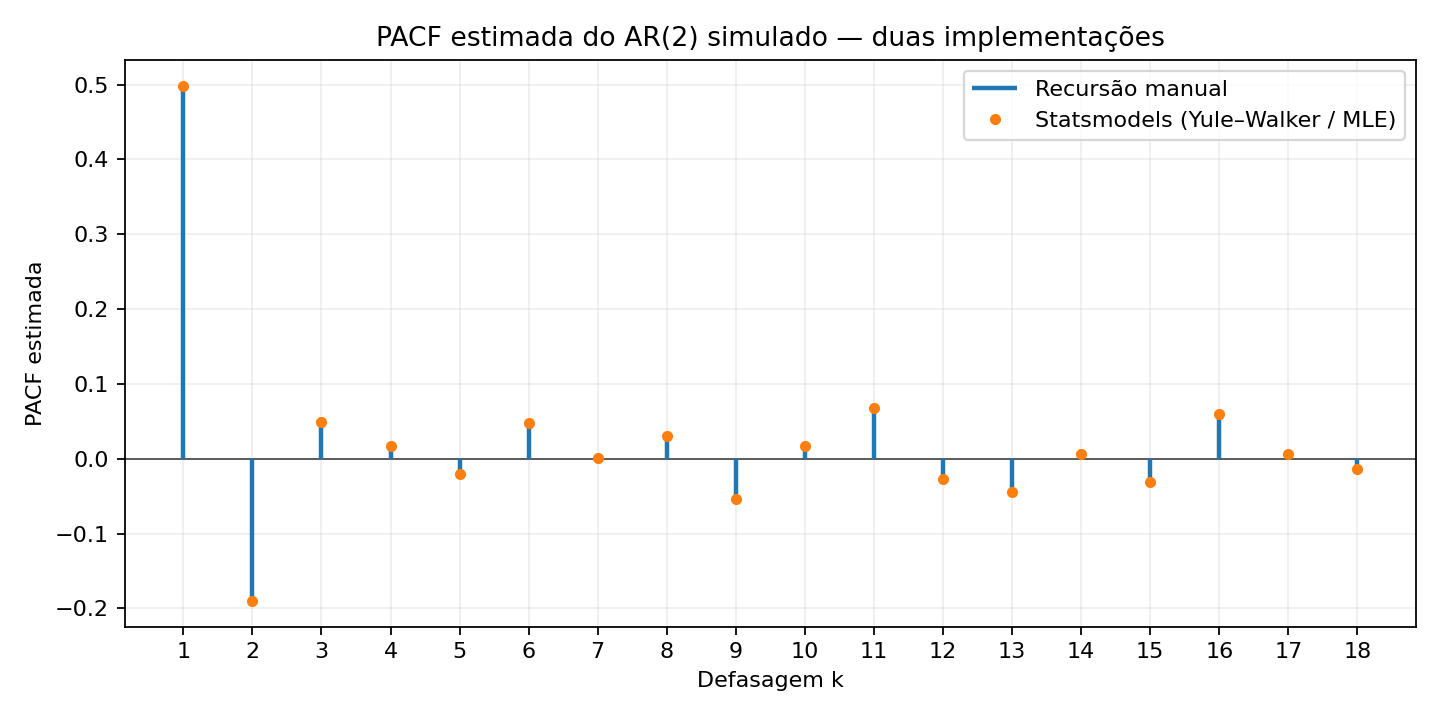

**Figura 1.** Comparação entre a recursão escrita manualmente e `statsmodels`, usando a mesma ACF amostral e a mesma convenção. A coincidência confirma a **implementação**, não constitui demonstração da estacionariedade do processo nem prova de que a PACF estimada seja idêntica à PACF populacional.

### 7. Interpretação estatística e limites

A redução de $v_k$ quando adicionamos variáveis explicativas é uma propriedade da **melhor projeção linear na população**. Em amostras finitas, a PACF não apresenta um corte perfeitamente exato mesmo que o processo gerador seja AR($p$). Além disso, valores de PACF próximos de zero não provam ausência de dependência não linear.

A recursão requer uma ACF coerente: a matriz Toeplitz deve ser positiva definida para garantir unicidade, divisões válidas e estabilidade. O estimador amostral da ACF e sua normalização alteram o resultado. Nunca confunda a PACF calculada de uma realização finita com os parâmetros exatos do modelo gerador.

### 8. Exercícios

1. **Conceitual:** por que o último coeficiente de uma regressão de ordem $k$ mede uma associação parcial, enquanto o coeficiente de ordem $k-1$ da regressão anterior não é a mesma quantidade?
2. **Cálculo:** com $\rho(1)=0{,}4$ e $\rho(2)=0{,}1$, calcule $\kappa_1$, $v_1$, $\kappa_2$ e $v_2$. Verifique se as variâncias normalizadas são positivas.
3. **Demonstração:** desenvolva $v_1=1-\rho(1)^2$ por expansão de uma variância; explique onde entra a estacionariedade fraca.
4. **Pseudocódigo:** escreva as etapas para calcular os coeficientes até $K=4$ antes de executar o código.
5. **Programação:** modifique o parâmetro $\phi_2$ da simulação de AR(2), mantendo o processo estacionário, e compare a PACF estimada com a teoria. Explique por que é preciso verificar a estacionariedade da escolha.

**Conferência selecionada do exercício 2:** $v_1=0{,}84$, $\kappa_2=(0{,}1-0{,}16)/0{,}84=-1/14\approx-0{,}07143$, $v_2=0{,}84(1-1/196)\approx0{,}83571$. Faça o cálculo antes de consultar esta resposta.

### Síntese e referências

A recursão de Levinson–Durbin explora a estrutura Toeplitz das equações de Yule–Walker para atualizar os parâmetros de projeção e obter a PACF em ordens sucessivas. É uma técnica de **projeção linear**, não um teste de independência ou causalidade.

**Referência primária consultada:** MORETTIN, P. A.; TOLOI, C. M. C. *Análise de Séries Temporais: modelos lineares univariados*. v. 1, 3. ed., Blucher, 2018, §5.2.5, pp. 138–139. **Complementação original:** dedução recursiva, verificações computacionais, simulação e exercícios desta seção.